# 🌾 Rice Leaf Disease Detection
### Multi-Disease Classification: CNN + CBAM Attention (YOLO-Inspired)
**Classes:** BrownSpot | Healthy | Hispa | LeafBlast


##  1. Input — Libraries, Dataset & Preprocessing

In [2]:
import subprocess, sys
def pip_install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg in ['tensorflow', 'scikit-learn', 'matplotlib', 'seaborn', 'Pillow', 'numpy', 'opencv-python']:
    pip_install(pkg)
print('✅ All packages ready.')


✅ All packages ready.


In [3]:
import os, random, warnings, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


In [4]:
TRAIN_DIR  = r'E:\Downloads\Rice Leaf Diseases dataset\Rice Leaf Diseases\train'
VAL_DIR    = r'E:\Downloads\Rice Leaf Diseases dataset\Rice Leaf Diseases\val'
MODEL_PATH = r'E:\Rice Leaf Disease minor project\model.h5'
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
EPOCHS      = 15
NUM_CLASSES = 4
CLASS_NAMES  = ['BrownSpot', 'Healthy', 'Hispa', 'LeafBlast']
CLASS_COLORS = ['#E74C3C', '#27AE60', '#F39C12', '#8E44AD']
SEVERITY_MAP = {'Mild': (0,25), 'Moderate': (25,50), 'Severe': (50,100)}
print(f'Train  : {TRAIN_DIR}')
print(f'Val    : {VAL_DIR}')
print(f'Model  : {MODEL_PATH}')


Train  : E:\Downloads\Rice Leaf Diseases dataset\Rice Leaf Diseases\train
Val    : E:\Downloads\Rice Leaf Diseases dataset\Rice Leaf Diseases\val
Model  : E:\Rice Leaf Disease minor project\model.h5


Class             Train      Val
-----------------------------------
BrownSpot           805      200
Healthy             869      217
Hispa               837      210
LeafBlast           863      216
TOTAL              3374      843


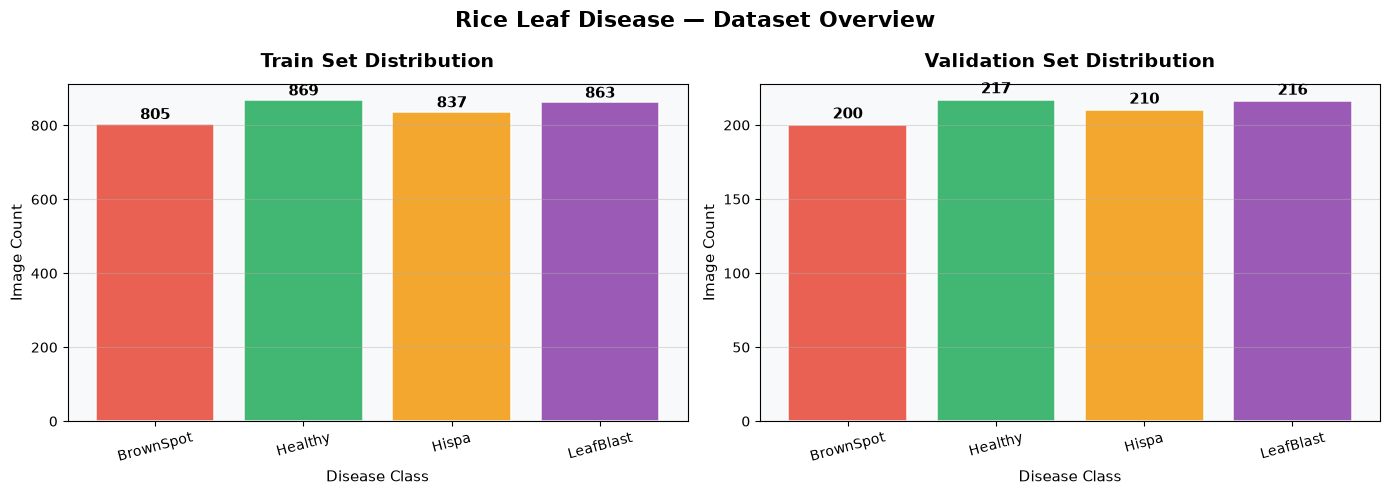

Distribution chart saved.


In [5]:
def count_images(base_dir, classes):
    counts = {}
    for cls in classes:
        folder = os.path.join(base_dir, cls)
        if os.path.exists(folder):
            counts[cls] = len([f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        else:
            counts[cls] = 0
    return counts

train_counts = count_images(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_images(VAL_DIR,   CLASS_NAMES)
print(f"{'Class':<14} {'Train':>8} {'Val':>8}")
print('-'*35)
for cls in CLASS_NAMES:
    print(f'{cls:<14} {train_counts[cls]:>8} {val_counts[cls]:>8}')
print(f"{'TOTAL':<14} {sum(train_counts.values()):>8} {sum(val_counts.values()):>8}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (split, counts) in zip(axes, [('Train', train_counts), ('Validation', val_counts)]):
    bars = ax.bar(CLASS_NAMES, counts.values(), color=CLASS_COLORS, alpha=0.88, edgecolor='white', linewidth=1.2)
    ax.set_title(f'{split} Set Distribution', fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel('Image Count', fontsize=11)
    ax.set_xlabel('Disease Class', fontsize=11)
    ax.tick_params(axis='x', rotation=15)
    ax.set_facecolor('#F8F9FA'); ax.grid(axis='y', alpha=0.4)
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2, str(val),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.suptitle('Rice Leaf Disease — Dataset Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\dataset_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Distribution chart saved.')


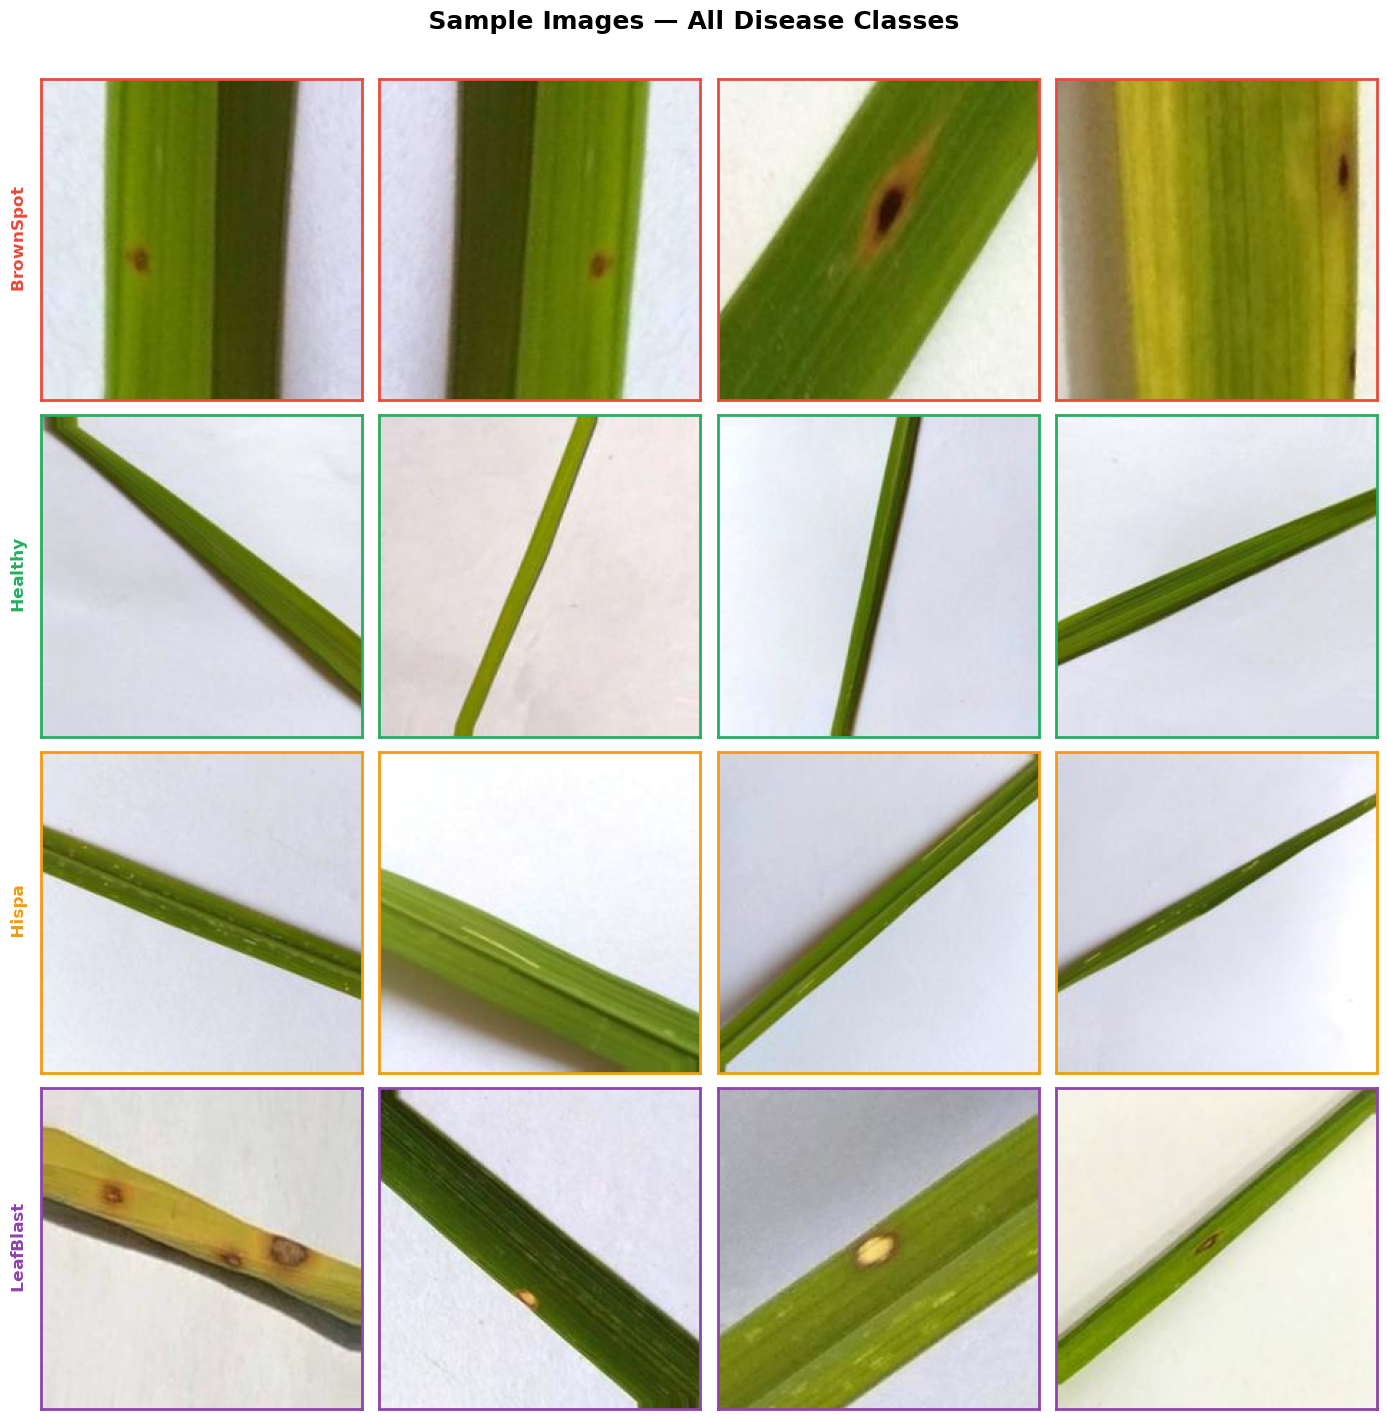

Sample images saved.


In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle('Sample Images — All Disease Classes', fontsize=18, fontweight='bold', y=1.01)
for row, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(TRAIN_DIR, cls)
    imgs   = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    sample = random.sample(imgs, min(4, len(imgs)))
    for col, fname in enumerate(sample):
        im = Image.open(os.path.join(folder, fname)).resize(IMG_SIZE)
        axes[row,col].imshow(im)
        if col == 0:
            axes[row,col].set_ylabel(cls, fontsize=12, fontweight='bold',
                                     color=CLASS_COLORS[row], rotation=90, labelpad=10)
        axes[row,col].set_xticks([]); axes[row,col].set_yticks([])
        for spine in axes[row,col].spines.values():
            spine.set_color(CLASS_COLORS[row]); spine.set_linewidth(2)
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sample images saved.')


In [8]:
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=30, width_shift_range=0.2,
    height_shift_range=0.2, shear_range=0.15, zoom_range=0.25,
    horizontal_flip=True, vertical_flip=True,
    brightness_range=[0.75, 1.25], channel_shift_range=20, fill_mode='reflect')
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASS_NAMES, shuffle=True, seed=SEED)
val_generator = val_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASS_NAMES, shuffle=False)

print(f'Train: {train_generator.samples} | Val: {val_generator.samples}')
print(f'Class indices: {train_generator.class_indices}')


Found 3374 images belonging to 4 classes.
Found 843 images belonging to 4 classes.
Train: 3374 | Val: 843
Class indices: {'BrownSpot': 0, 'Healthy': 1, 'Hispa': 2, 'LeafBlast': 3}


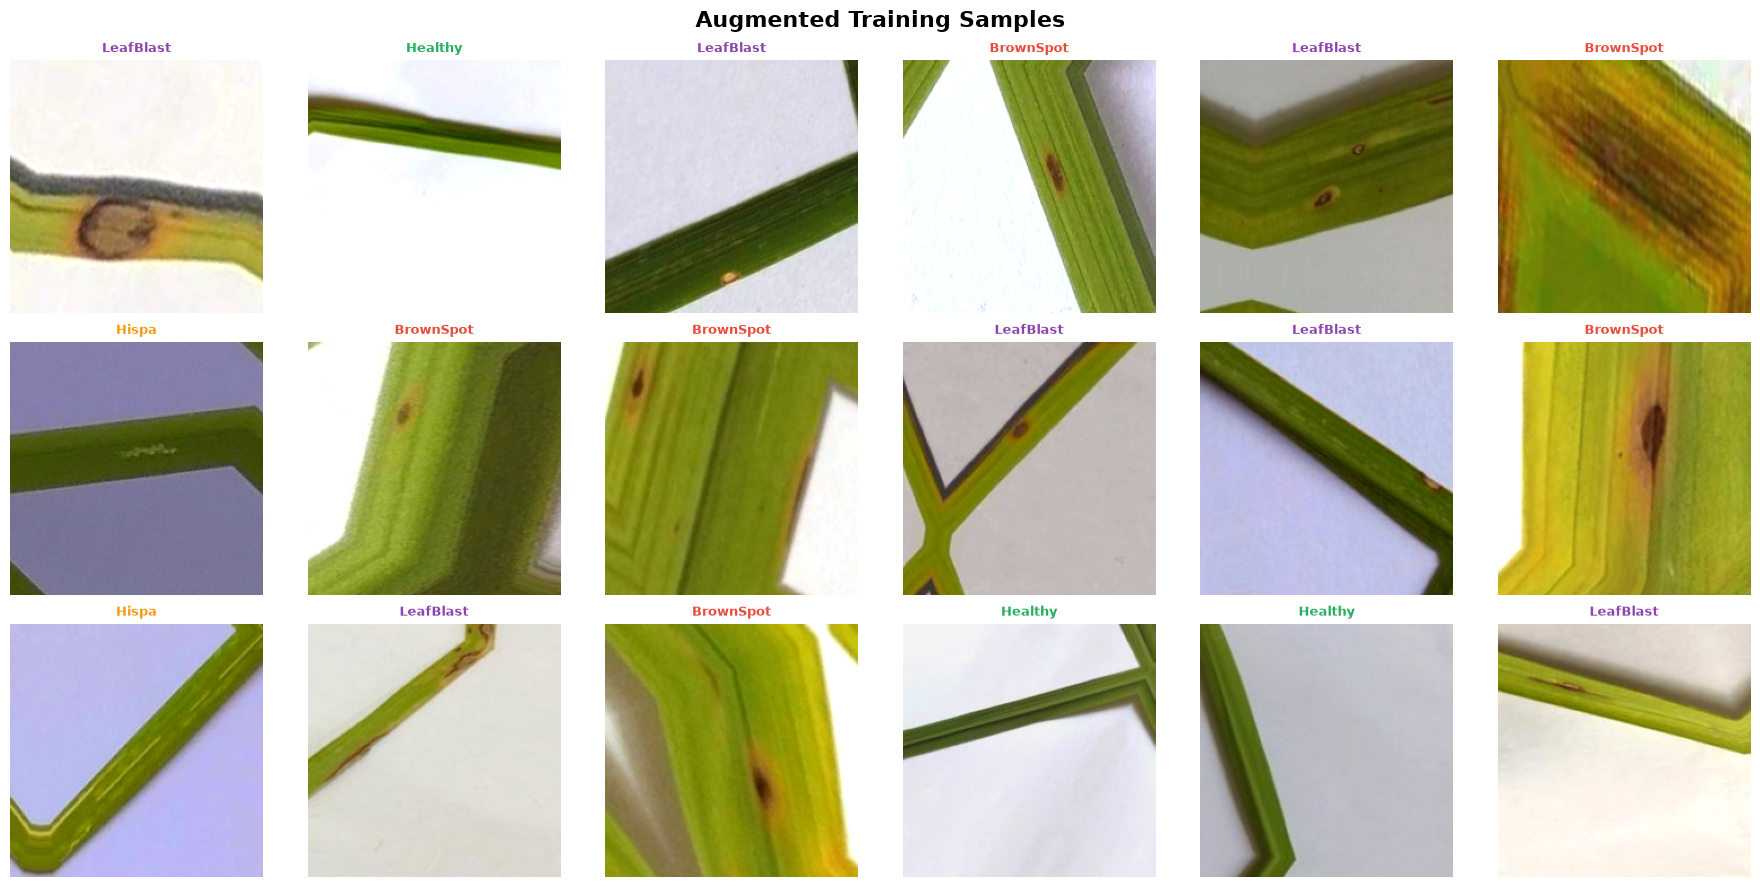

In [9]:
imgs, labels = next(train_generator)
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
fig.suptitle('Augmented Training Samples', fontsize=16, fontweight='bold')
for i, ax in enumerate(axes.flat):
    if i < len(imgs):
        ax.imshow(imgs[i])
        ci = np.argmax(labels[i])
        ax.set_title(CLASS_NAMES[ci], fontsize=9, color=CLASS_COLORS[ci], fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\augmented_samples.png', dpi=120, bbox_inches='tight')
plt.show()


##  2. Model — CNN + CBAM Attention Architecture

In [10]:
# ── Channel Attention (WHAT to focus on) ─────────────────────────────────
def channel_attention(x, ratio=8):
    channels  = x.shape[-1]
    shared_d1 = layers.Dense(channels // ratio, activation='relu',
                              kernel_initializer='he_normal', use_bias=False)
    shared_d2 = layers.Dense(channels, kernel_initializer='he_normal', use_bias=False)
    avg = layers.Reshape((1, 1, channels))(layers.GlobalAveragePooling2D()(x))
    avg = shared_d2(shared_d1(avg))
    mx  = layers.Reshape((1, 1, channels))(layers.GlobalMaxPooling2D()(x))
    mx  = shared_d2(shared_d1(mx))
    att = layers.Activation('sigmoid')(layers.Add()([avg, mx]))
    return layers.Multiply()([x, att])

# ── Spatial Attention (WHERE to focus on) ────────────────────────────────────
class ReduceMeanLayer(layers.Layer):
    def call(self, x):
        return tf.reduce_mean(x, axis=-1, keepdims=True)

class ReduceMaxLayer(layers.Layer):
    def call(self, x):
        return tf.reduce_max(x, axis=-1, keepdims=True)

def spatial_attention(x, kernel_size=7):
    avg_p = ReduceMeanLayer()(x)
    max_p = ReduceMaxLayer()(x)
    cat   = layers.Concatenate(axis=-1)([avg_p, max_p])
    att   = layers.Conv2D(1, kernel_size, padding='same',
                           activation='sigmoid', use_bias=False)(cat)
    return layers.Multiply()([x, att])

# ── Full CBAM Block ───────────────────────────────────────────────────────────
def cbam_block(x, ratio=8, kernel_size=7):
    x = channel_attention(x, ratio=ratio)
    x = spatial_attention(x, kernel_size=kernel_size)
    return x

# ── YOLO DarkNet-style Conv Block ────────────────────────────────────────────
def dark_conv_block(x, filters, kernel_size, strides=1):
    padding = 'same' if strides == 1 else 'valid'
    if strides == 2:
        x = layers.ZeroPadding2D(((1, 0), (1, 0)))(x)
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding=padding,
                      use_bias=False, kernel_initializer='he_normal',
                      kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    return x

# ── Residual Block + optional CBAM ────────────────────────────────────────────
def residual_cbam_block(x, filters, use_cbam=True):
    shortcut = x
    x = dark_conv_block(x, filters // 2, 1)
    x = dark_conv_block(x, filters,      3)
    if use_cbam:
        x = cbam_block(x)
    return layers.Add()([shortcut, x])

print('✅ CBAM attention modules defined.')


✅ CBAM attention modules defined.


In [11]:
def build_rice_cbam_model(input_shape=(224, 224, 3), num_classes=4):
    inputs = keras.Input(shape=input_shape, name='input_image')
    # Stage 0: Stem (224x224)
    x = dark_conv_block(inputs, 32, 3)
    # Stage 1: 112x112
    x = dark_conv_block(x, 64, 3, strides=2)
    x = residual_cbam_block(x, 64, use_cbam=False)
    # Stage 2: 56x56
    x = dark_conv_block(x, 128, 3, strides=2)
    for _ in range(2): x = residual_cbam_block(x, 128, use_cbam=False)
    # Stage 3: 28x28 — Channel+Spatial Attention
    x = dark_conv_block(x, 256, 3, strides=2)
    for _ in range(4): x = residual_cbam_block(x, 256, use_cbam=True)
    # Stage 4: 14x14 — Channel+Spatial Attention
    x = dark_conv_block(x, 512, 3, strides=2)
    for _ in range(4): x = residual_cbam_block(x, 512, use_cbam=True)
    # Stage 5: 7x7 — Deep CBAM
    x = dark_conv_block(x, 1024, 3, strides=2)
    for _ in range(2): x = residual_cbam_block(x, 1024, use_cbam=True)
    x = cbam_block(x, ratio=16, kernel_size=5)
    # Classification Head
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=keras.regularizers.l2(1e-4), name='fc1')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5, seed=SEED)(x)
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=keras.regularizers.l2(1e-4), name='fc2')(x)
    x = layers.Dropout(0.3, seed=SEED)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    return Model(inputs, outputs, name='RiceCBAM_v1')

model = build_rice_cbam_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')])
model.summary(line_length=100)
print(f'Total params: {model.count_params():,}')


Model: "RiceCBAM_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d (Conv2D)             │ (None, 224, 224, 32)    │            864 │ input_image[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization         │ (None, 224, 224, 32)    │            128 │ conv2d[0][0]            │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ leaky_re_lu (LeakyReLU)     │ (None, 224, 224, 32)    │              0 │ batch_normalization[0]… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ zero_padding2d              │ (None, 225, 225, 32)    │              0 │ leaky_re_lu[0][0]       │
│ (ZeroPadding2D)             │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_1 (Conv2D)           │ (None, 112, 112, 64)    │         18,432 │ zero_padding2d[0][0]    │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_1       │ (None, 112, 112, 64)    │            256 │ conv2d_1[0][0]          │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ leaky_re_lu_1 (LeakyReLU)   │ (None, 112, 112, 64)    │              0 │ batch_normalization_1[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_2 (Conv2D)           │ (None, 112, 112, 32)    │          2,048 │ leaky_re_lu_1[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_2       │ (None, 112, 112, 32)    │            128 │ conv2d_2[0][0]          │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ leaky_re_lu_2 (LeakyReLU)   │ (None, 112, 112, 32)    │              0 │ batch_normalization_2[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_3 (Conv2D)           │ (None, 112, 112, 64)    │         18,432 │ leaky_re_lu_2[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_3       │ (None, 112, 112, 64)    │            256 │ conv2d_3[0][0]          │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ leaky_re_lu_3 (LeakyReLU)   │ (None, 112, 112, 64)    │              0 │ batch_normalization_3[… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ add (Add)                   │ (None, 112, 112, 64)    │              0 │ leaky_re_lu_1[0][0],    │
│                             │                         │                │ leaky_re_lu_3[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ zero_padding2d_1            │ (None, 113, 113, 64)    │    

 Total params: 25,193,834 (96.11 MB)

 Trainable params: 25,172,458 (96.03 MB)

 Non-trainable params: 21,376 (83.50 KB)

Total params: 25,193,834


In [12]:
# Class weights
labels_flat = train_generator.classes
cw_array    = compute_class_weight(class_weight='balanced',
                                    classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = dict(enumerate(cw_array))
print('Class Weights:')
for idx, cls in enumerate(CLASS_NAMES):
    print(f'  {cls:<14} -> {class_weight_dict[idx]:.4f}')

# Callbacks
callbacks = [
    ModelCheckpoint(MODEL_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=5, min_lr=1e-7, verbose=1)
]
print('\n✅ Callbacks ready.')


Class Weights:
  BrownSpot      -> 1.0478
  Healthy        -> 0.9707
  Hispa          -> 1.0078
  LeafBlast      -> 0.9774

✅ Callbacks ready.


In [13]:
# Set the number of epochs

print('🚀 Starting Training...')
print(f'   Epochs     : {EPOCHS}')
print(f'   Batch size : {BATCH_SIZE}')
print(f'   Steps/ep   : {len(train_generator)}')

history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=len(val_generator),
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

best_ep = np.argmax(history.history['val_accuracy'])

print('\n✅ Training complete!')
print(f'   Best Epoch    : {best_ep + 1}')
print(f'   Best Val Acc  : {history.history["val_accuracy"][best_ep] * 100:.2f}%')

🚀 Starting Training...
   Epochs     : 15
   Batch size : 32
   Steps/ep   : 106
Epoch 1/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5679 - loss: 3.1756 - precision: 0.6074 - recall: 0.4911
Epoch 1: val_accuracy improved from None to 0.59905, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 1: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 532s 5s/step - accuracy: 0.5679 - loss: 3.1756 - precision: 0.6074 - recall: 0.4911 - val_accuracy: 0.5991 - val_loss: 3.3224 - val_precision: 0.6884 - val_recall: 0.3250 - learning_rate: 0.0010
Epoch 2/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6660 - loss: 2.7546 - precision: 0.7144 - recall: 0.5990
Epoch 2: val_accuracy did not improve from 0.59905
106/106 ━━━━━━━━━━━━━━━━━━━━ 518s 5s/step - accuracy: 0.6660 - loss: 2.7546 - precision: 0.7144 - recall: 0.5990 - val_accuracy: 0.4899 - val_loss: 3.0916 - val_precision: 0.5444 - val_recall: 0.3998 - learning_rate: 0.0010
Epoch 3/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7196 - loss: 2.4281 - precision: 0.7529 - recall: 0.6636
Epoch 3: val_accuracy improved from 0.59905 to 0.77580, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 3: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 522s 5s/step - accuracy: 0.7196 - loss: 2.4281 - precision: 0.7529 - recall: 0.6636 - val_accuracy: 0.7758 - val_loss: 2.1404 - val_precision: 0.7891 - val_recall: 0.7414 - learning_rate: 0.0010
Epoch 4/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7493 - loss: 2.1254 - precision: 0.7645 - recall: 0.7170
Epoch 4: val_accuracy did not improve from 0.77580
106/106 ━━━━━━━━━━━━━━━━━━━━ 480s 5s/step - accuracy: 0.7493 - loss: 2.1254 - precision: 0.7645 - recall: 0.7170 - val_accuracy: 0.6560 - val_loss: 2.3918 - val_precision: 0.6597 - val_recall: 0.6394 - learning_rate: 0.0010
Epoch 5/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7733 - loss: 1.8827 - precision: 0.7853 - recall: 0.7490
Epoch 5: val_accuracy did not improve from 0.77580
106/106 ━━━━━━━━━━━━━━━━━━━━ 509s 5s/step - accuracy: 0.7733 - loss: 1.8827 - precision: 0.7853 - recall: 0.7490 - val_accuracy


Epoch 10: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 524s 5s/step - accuracy: 0.8660 - loss: 1.0879 - precision: 0.8726 - recall: 0.8568 - val_accuracy: 0.7794 - val_loss: 1.2700 - val_precision: 0.8030 - val_recall: 0.7592 - learning_rate: 0.0010
Epoch 11/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9046 - loss: 0.9299 - precision: 0.9085 - recall: 0.8977
Epoch 11: val_accuracy improved from 0.77936 to 0.79359, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 11: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 515s 5s/step - accuracy: 0.9046 - loss: 0.9299 - precision: 0.9085 - recall: 0.8977 - val_accuracy: 0.7936 - val_loss: 1.1479 - val_precision: 0.8005 - val_recall: 0.7900 - learning_rate: 0.0010
Epoch 12/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8915 - loss: 0.9028 - precision: 0.8973 - recall: 0.8853
Epoch 12: val_accuracy improved from 0.79359 to 0.90629, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 12: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 523s 5s/step - accuracy: 0.8915 - loss: 0.9028 - precision: 0.8973 - recall: 0.8853 - val_accuracy: 0.9063 - val_loss: 0.8403 - val_precision: 0.9062 - val_recall: 0.9051 - learning_rate: 0.0010
Epoch 13/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9179 - loss: 0.7783 - precision: 0.9213 - recall: 0.9155
Epoch 13: val_accuracy did not improve from 0.90629
106/106 ━━━━━━━━━━━━━━━━━━━━ 505s 5s/step - accuracy: 0.9179 - loss: 0.7783 - precision: 0.9213 - recall: 0.9155 - val_accuracy: 0.8932 - val_loss: 0.8104 - val_precision: 0.8992 - val_recall: 0.8885 - learning_rate: 0.0010
Epoch 14/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9235 - loss: 0.7235 - precision: 0.9276 - recall: 0.9194
Epoch 14: val_accuracy improved from 0.90629 to 0.91815, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 14: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 525s 5s/step - accuracy: 0.9235 - loss: 0.7235 - precision: 0.9276 - recall: 0.9194 - val_accuracy: 0.9181 - val_loss: 0.6858 - val_precision: 0.9203 - val_recall: 0.9181 - learning_rate: 0.0010
Epoch 15/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9226 - loss: 0.7004 - precision: 0.9244 - recall: 0.9200
Epoch 15: val_accuracy improved from 0.91815 to 0.97034, saving model to E:\Rice Leaf Disease minor project\model.h5



Epoch 15: finished saving model to E:\Rice Leaf Disease minor project\model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 525s 5s/step - accuracy: 0.9226 - loss: 0.7004 - precision: 0.9244 - recall: 0.9200 - val_accuracy: 0.9703 - val_loss: 0.5735 - val_precision: 0.9703 - val_recall: 0.9692 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 15.

✅ Training complete!
   Best Epoch    : 15
   Best Val Acc  : 97.03%


##  3. Save Model

In [44]:
# Save model.h5
model.save(MODEL_PATH)
file_size_mb = os.path.getsize(MODEL_PATH) / (1024**2)
print('=' * 55)
print('  💾  Model Saved Successfully')
print('=' * 55)
print(f'  Path   : {MODEL_PATH}')
print(f'  Size   : {file_size_mb:.2f} MB')
print(f'  Classes: {CLASS_NAMES}')

# Save metadata JSON for the API backend
metadata = {
    'class_names'        : CLASS_NAMES,
    'class_indices'      : train_generator.class_indices,
    'img_size'           : list(IMG_SIZE),
    'num_classes'        : NUM_CLASSES,
    'model_path'         : MODEL_PATH,
    'severity_thresholds': {k: list(v) for k, v in SEVERITY_MAP.items()},
    'architecture'       : 'YOLO-Backbone + CBAM (Channel + Spatial Attention)'
}
meta_path = r'E:\Rice Leaf Disease minor project\model_metadata.json'
with open(meta_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f'  Metadata : {meta_path}')
print('  (Use this in your Flask/FastAPI backend)')


  💾  Model Saved Successfully
  Path   : E:\Rice Leaf Disease minor project\model.keras
  Size   : 96.94 MB
  Classes: ['BrownSpot', 'Healthy', 'Hispa', 'LeafBlast']
  Metadata : E:\Rice Leaf Disease minor project\model_metadata.json
  (Use this in your Flask/FastAPI backend)


In [48]:
MODEL_PATH = r'E:\Rice Leaf Disease minor project\model.keras'

# 1. Remove Lambda layers from spatial_attention and transfer your trained weights
def spatial_attention(x, kernel_size=7):
    avg_p = keras.ops.mean(x, axis=-1, keepdims=True)
    max_p = keras.ops.max(x, axis=-1, keepdims=True)
    cat   = layers.Concatenate(axis=-1)([avg_p, max_p])
    att   = layers.Conv2D(1, kernel_size, padding='same',
                          activation='sigmoid', use_bias=False)(cat)
    return layers.Multiply()([x, att])

clean_model = build_rice_cbam_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES)
clean_model.set_weights(model.get_weights())  # Copies trained weights directly from memory
clean_model.save(MODEL_PATH)                  # Overwrites model.keras without Lambda layers

# 2. Your Sanity Check (Now loads cleanly without safe_mode or Lambda errors)
loaded_model = keras.models.load_model(MODEL_PATH)
print(f'Input  : {loaded_model.input_shape}')
print(f'Output : {loaded_model.output_shape}')
dummy = np.random.rand(1, *IMG_SIZE, 3).astype(np.float32)
out   = loaded_model.predict(dummy, verbose=0)
print(f'Sanity : {out.shape} -> {CLASS_NAMES[np.argmax(out[0])]}')

Input  : (None, 224, 224, 3)
Output : (None, 4)
Sanity : (1, 4) -> LeafBlast


##  4. Evaluate — Training History & Metrics

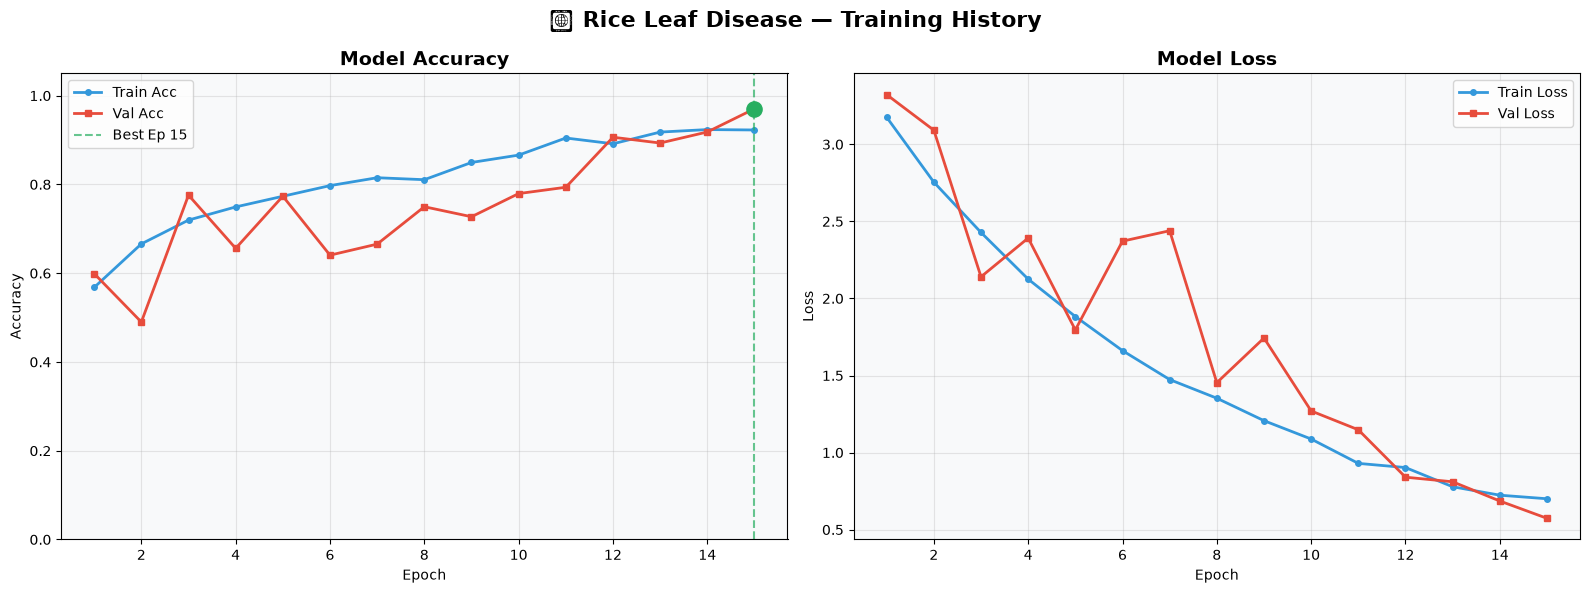

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ep = range(1, len(history.history['accuracy']) + 1)

ax = axes[0]
ax.plot(ep, history.history['accuracy'],     'o-', color='#3498DB', lw=2, ms=4, label='Train Acc')
ax.plot(ep, history.history['val_accuracy'], 's-', color='#E74C3C', lw=2, ms=4, label='Val Acc')
best_ep = np.argmax(history.history['val_accuracy'])
ax.axvline(x=best_ep+1, color='#27AE60', ls='--', alpha=0.7, label=f'Best Ep {best_ep+1}')
ax.scatter(best_ep+1, history.history['val_accuracy'][best_ep], color='#27AE60', s=120, zorder=5)
ax.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_facecolor('#F8F9FA'); ax.set_ylim([0, 1.05])

ax = axes[1]
ax.plot(ep, history.history['loss'],     'o-', color='#3498DB', lw=2, ms=4, label='Train Loss')
ax.plot(ep, history.history['val_loss'], 's-', color='#E74C3C', lw=2, ms=4, label='Val Loss')
ax.set_title('Model Loss', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_facecolor('#F8F9FA')

plt.suptitle('🌾 Rice Leaf Disease — Training History', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\training_history.png', dpi=150, bbox_inches='tight')
plt.show()


In [53]:
# ─── Validation Evaluation & Classification Report ───────────────────────────

# 1. Ensure the loaded model is compiled with your metrics
loaded_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

# 2. Evaluate on Validation Set
val_generator.reset()
results      = loaded_model.evaluate(val_generator, verbose=1)
metric_names = loaded_model.metrics_names

print('\nValidation Metrics')
print('=' * 40)
for name, val in zip(metric_names, results):
    if name == 'loss': print(f'  {name:<12}: {val:.4f}')
    else:              print(f'  {name:<12}: {val:.4f}  ({val*100:.2f}%)')

# 3. Generate Classification Report
val_generator.reset()
y_pred_proba = loaded_model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_proba, axis=1)
y_true = val_generator.classes

print('\n📋 Per-Class Classification Report')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

27/27 ━━━━━━━━━━━━━━━━━━━━ 32s 995ms/step - accuracy: 0.9703 - loss: 0.5735 - precision: 0.9703 - recall: 0.9692

Validation Metrics
  loss        : 0.5735
  compile_metrics: 0.9703  (97.03%)
27/27 ━━━━━━━━━━━━━━━━━━━━ 28s 986ms/step

📋 Per-Class Classification Report
              precision    recall  f1-score   support

   BrownSpot     0.9900    0.9900    0.9900       200
     Healthy     0.9856    0.9447    0.9647       217
       Hispa     0.9234    0.9762    0.9491       210
   LeafBlast     0.9859    0.9722    0.9790       216

    accuracy                         0.9703       843
   macro avg     0.9712    0.9708    0.9707       843
weighted avg     0.9712    0.9703    0.9705       843



##  5. Confusion Matrix

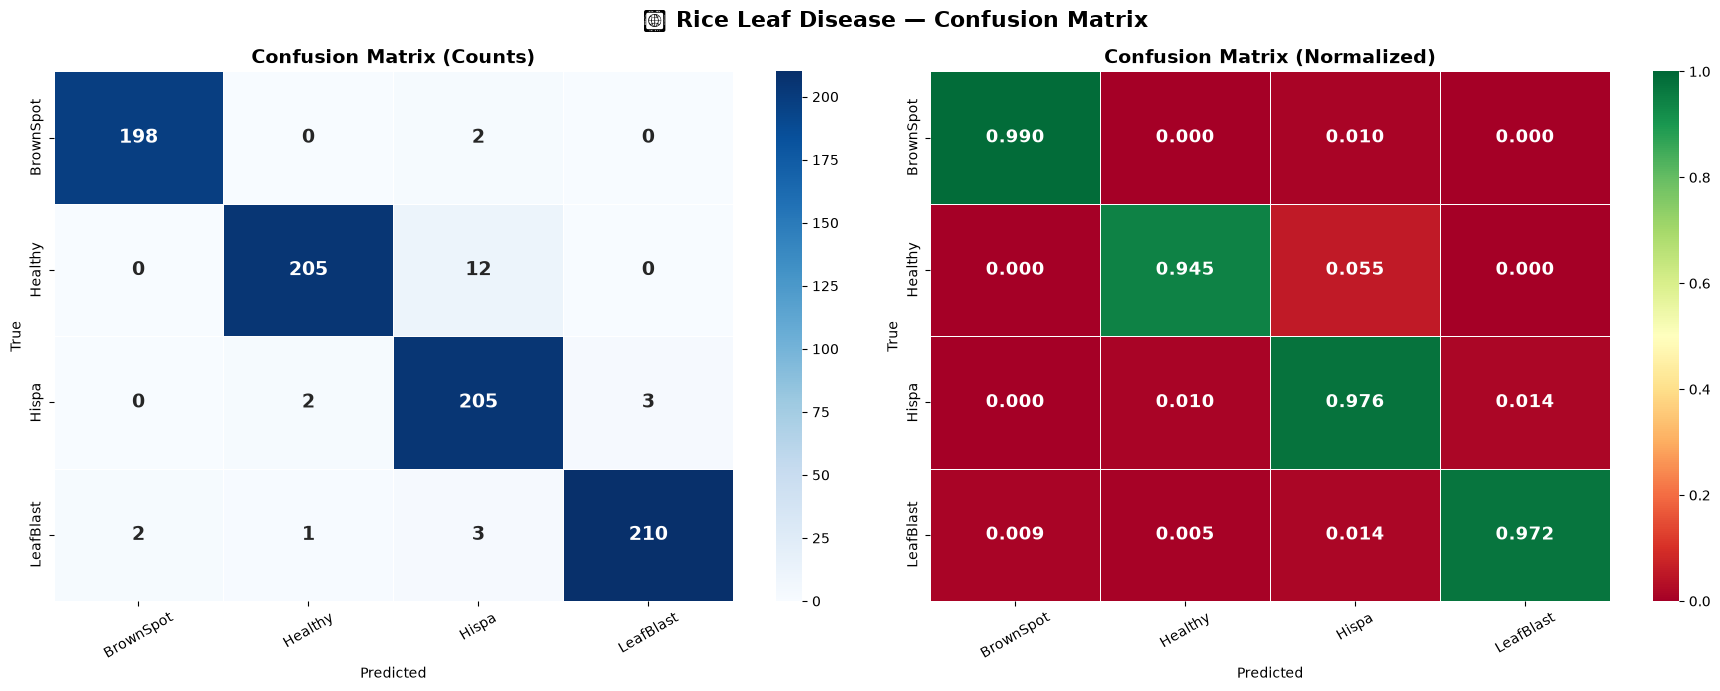

Confusion matrix saved.


In [54]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='white', ax=axes[0],
            annot_kws={'size': 14, 'fontweight': 'bold'})
axes[0].set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='RdYlGn',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            vmin=0, vmax=1, linewidths=0.5, linecolor='white', ax=axes[1],
            annot_kws={'size': 13, 'fontweight': 'bold'})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('🌾 Rice Leaf Disease — Confusion Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Confusion matrix saved.')


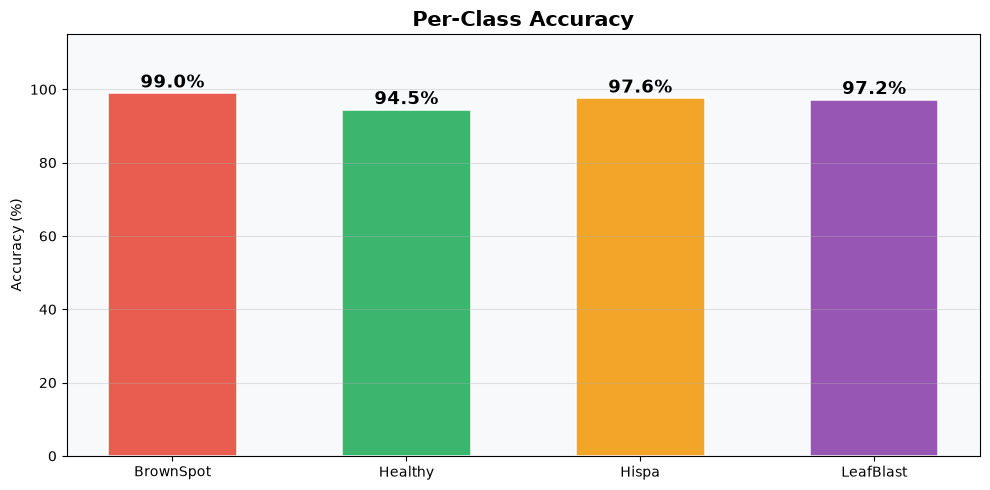

In [55]:
per_class_acc = cm_norm.diagonal()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(CLASS_NAMES, per_class_acc * 100, color=CLASS_COLORS,
              alpha=0.9, edgecolor='white', linewidth=1.2, width=0.55)
ax.set_title('Per-Class Accuracy', fontsize=15, fontweight='bold')
ax.set_ylabel('Accuracy (%)'); ax.set_ylim([0, 115])
ax.set_facecolor('#F8F9FA'); ax.grid(axis='y', alpha=0.35)
for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{acc*100:.1f}%', ha='center', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(r'E:\Rice Leaf Disease minor project\per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


##  6. Test Random — Predict on Random Images with Severity Estimation

In [56]:
def preprocess_image(img_path, target_size=IMG_SIZE):
    img = Image.open(img_path).convert('RGB')
    arr = np.array(img.resize(target_size), dtype=np.float32) / 255.0
    return arr[np.newaxis, ...]

def estimate_severity(img_path):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None: return 0.0, 'Unknown'
    img_hsv  = cv2.cvtColor(cv2.resize(img_bgr, (224,224)), cv2.COLOR_BGR2HSV)
    leaf_mask = cv2.inRange(img_hsv, np.array([25,40,40]),  np.array([95,255,255]))
    dis_mask1 = cv2.inRange(img_hsv, np.array([5, 40,40]),  np.array([25,255,220]))
    dis_mask2 = cv2.inRange(img_hsv, np.array([0, 0, 0]),   np.array([180,255,60]))
    disease_mask = cv2.bitwise_or(dis_mask1, dis_mask2)
    leaf_px = cv2.countNonZero(leaf_mask)
    dis_px  = cv2.countNonZero(disease_mask)
    total   = leaf_px + dis_px
    if total == 0: return 0.0, 'Healthy'
    sev_pct = min((dis_px / total) * 100, 100.0)
    level   = 'Mild' if sev_pct < 25 else ('Moderate' if sev_pct < 50 else 'Severe')
    return round(sev_pct, 1), level

def predict_image(img_path, model, class_names=CLASS_NAMES):
    probs      = model.predict(preprocess_image(img_path), verbose=0)[0]
    pred_idx   = np.argmax(probs)
    disease    = class_names[pred_idx]
    confidence = probs[pred_idx] * 100
    sev_pct, sev_lvl = estimate_severity(img_path)
    if disease == 'Healthy': sev_pct, sev_lvl = 0.0, 'None'
    return disease, round(confidence, 2), sev_pct, sev_lvl, probs

print('✅ Prediction utilities ready.')


✅ Prediction utilities ready.


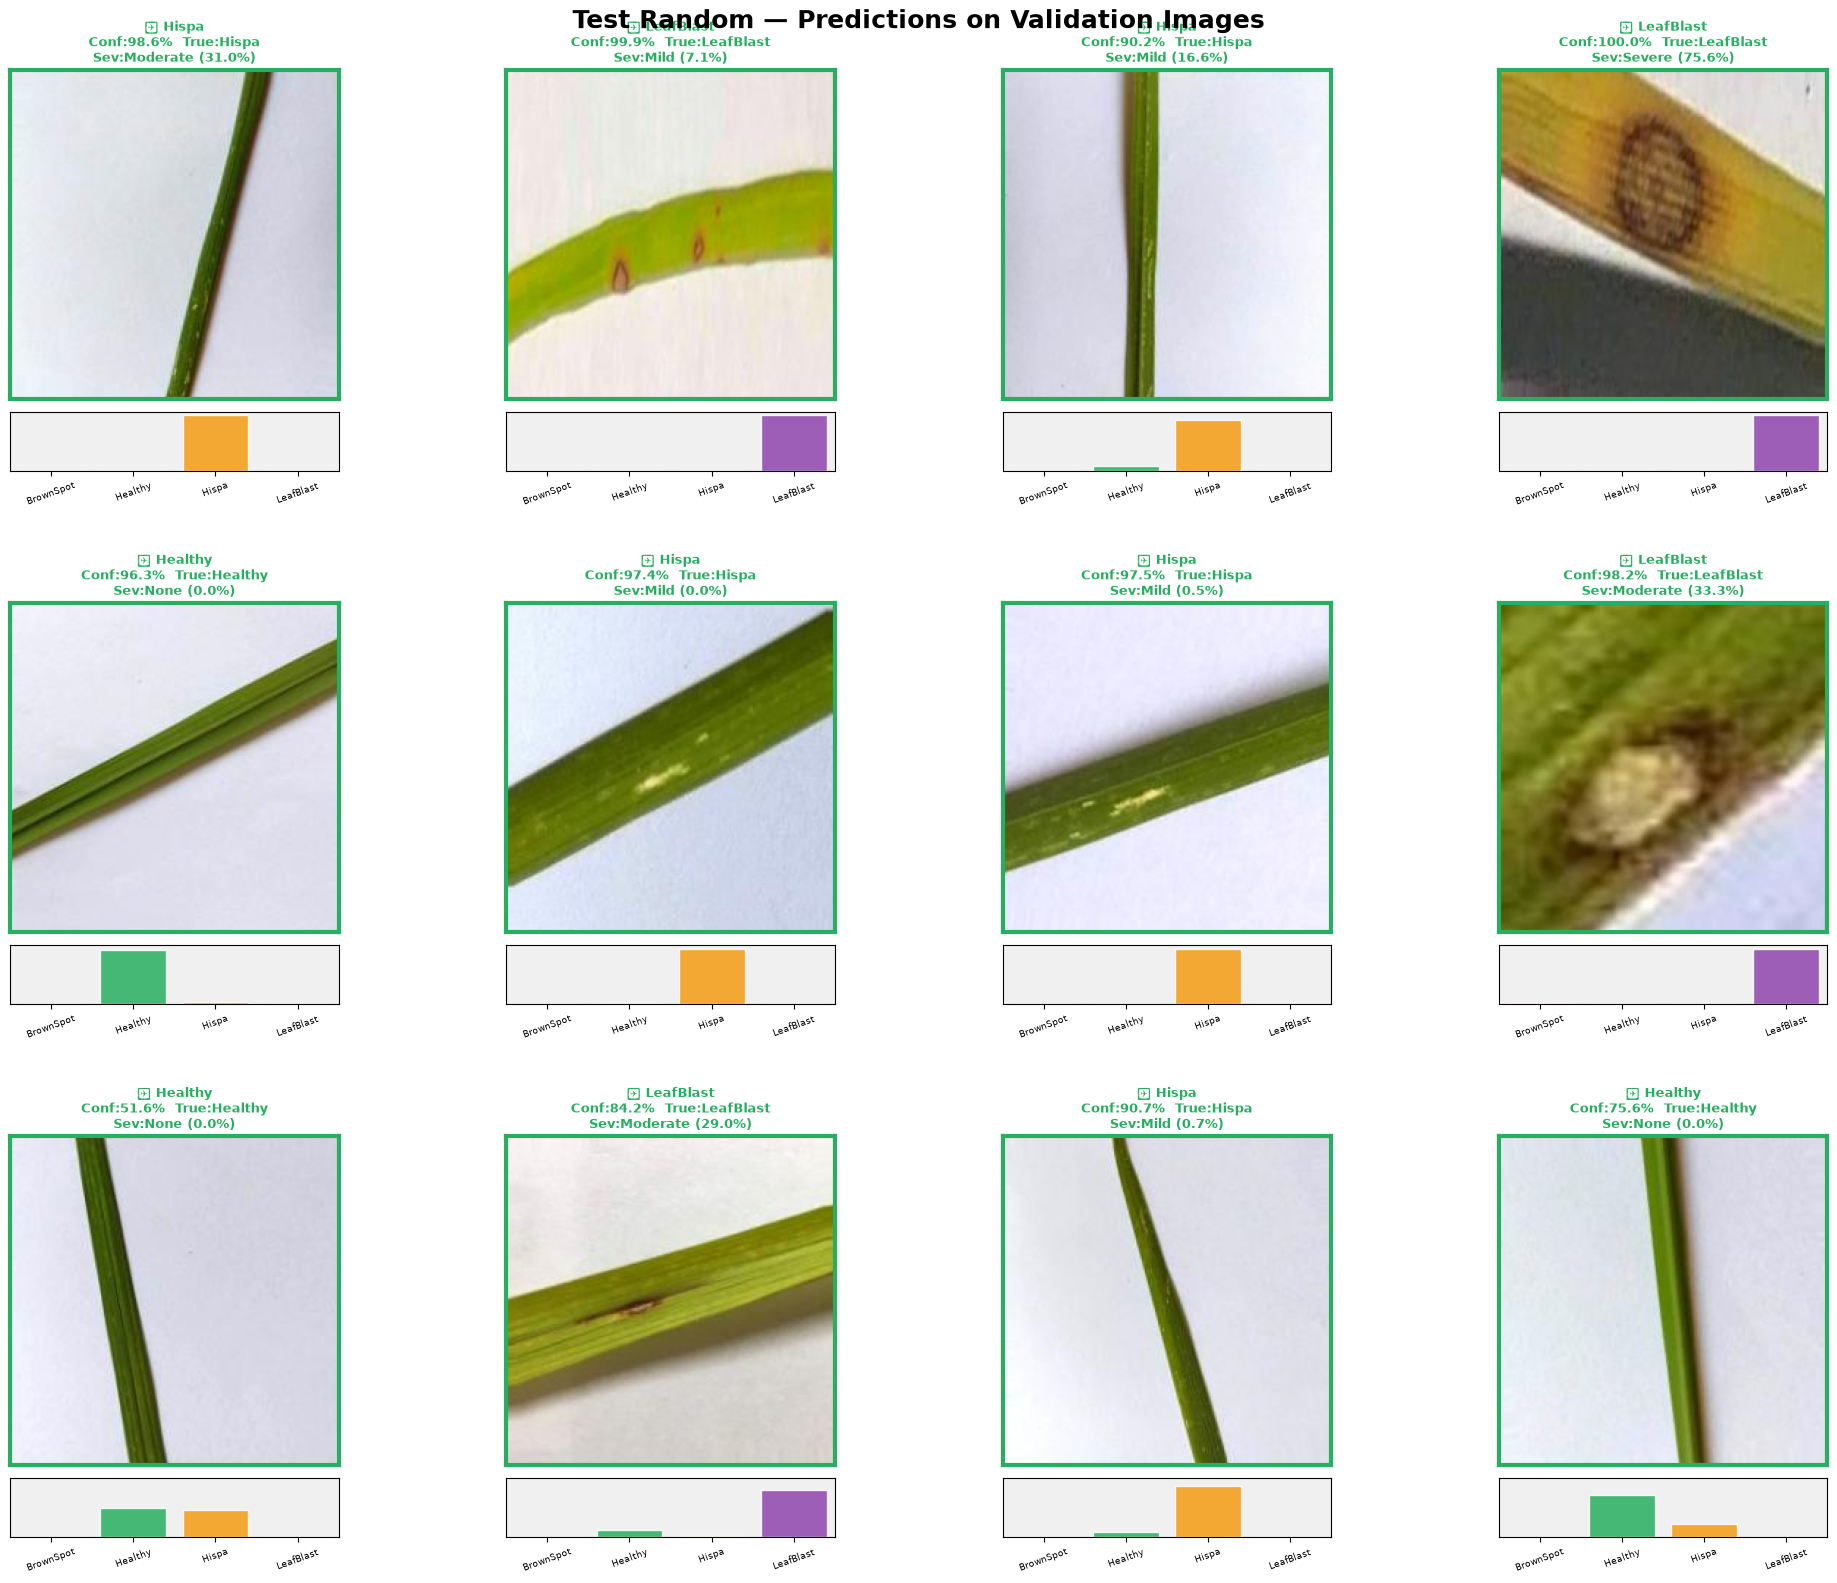

Test random predictions saved.


In [57]:
all_val_images = []
for cls in CLASS_NAMES:
    folder = os.path.join(VAL_DIR, cls)
    files  = [os.path.join(folder, f) for f in os.listdir(folder)
               if f.lower().endswith(('.jpg','.jpeg','.png'))]
    all_val_images += [(fp, cls) for fp in files]

random.shuffle(all_val_images)
sample_images = all_val_images[:12]

SEV_COLORS = {'None':'#27AE60','Mild':'#F1C40F','Moderate':'#E67E22','Severe':'#E74C3C'}
fig, axes  = plt.subplots(3, 4, figsize=(20, 16))
fig.suptitle('Test Random — Predictions on Validation Images',
             fontsize=18, fontweight='bold')

# Fix: use numeric x-positions to avoid matplotlib categorical/numeric mix conflict
x_pos = np.arange(len(CLASS_NAMES))

for ax, (img_path, true_cls) in zip(axes.flat, sample_images):
    disease, conf, sev_pct, sev_lvl, probs = predict_image(img_path, model)
    ax.imshow(Image.open(img_path).resize(IMG_SIZE))
    correct    = (disease == true_cls)
    border_clr = '#27AE60' if correct else '#E74C3C'
    for spine in ax.spines.values():
        spine.set_edgecolor(border_clr); spine.set_linewidth(3)
    status = '\u2705' if correct else '\u274c'
    title_str = '{} {}\nConf:{:.1f}%  True:{}\nSev:{} ({:.1f}%)'.format(
        status, disease, conf, true_cls, sev_lvl, sev_pct)
    ax.set_title(title_str, fontsize=9, fontweight='bold', color=border_clr)
    ax.set_xticks([]); ax.set_yticks([])
    bx = ax.inset_axes([0, -0.22, 1, 0.18])
    # Use numeric positions + explicit tick labels to avoid StrCategoryConverter conflict
    bx.bar(x_pos, probs * 100, color=CLASS_COLORS, alpha=0.85, edgecolor='white')
    bx.set_xlim([-0.5, len(CLASS_NAMES) - 0.5])
    bx.set_xticks(x_pos)
    bx.set_xticklabels(CLASS_NAMES, fontsize=6.5, rotation=20)
    bx.set_ylim([0, 105]); bx.set_yticks([])
    bx.set_facecolor('#F0F0F0')

plt.tight_layout(h_pad=5)
plt.savefig(r'E:\Rice Leaf Disease minor project\test_random_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Test random predictions saved.')


Testing: dr_89_1477.jpg (True: LeafBlast)


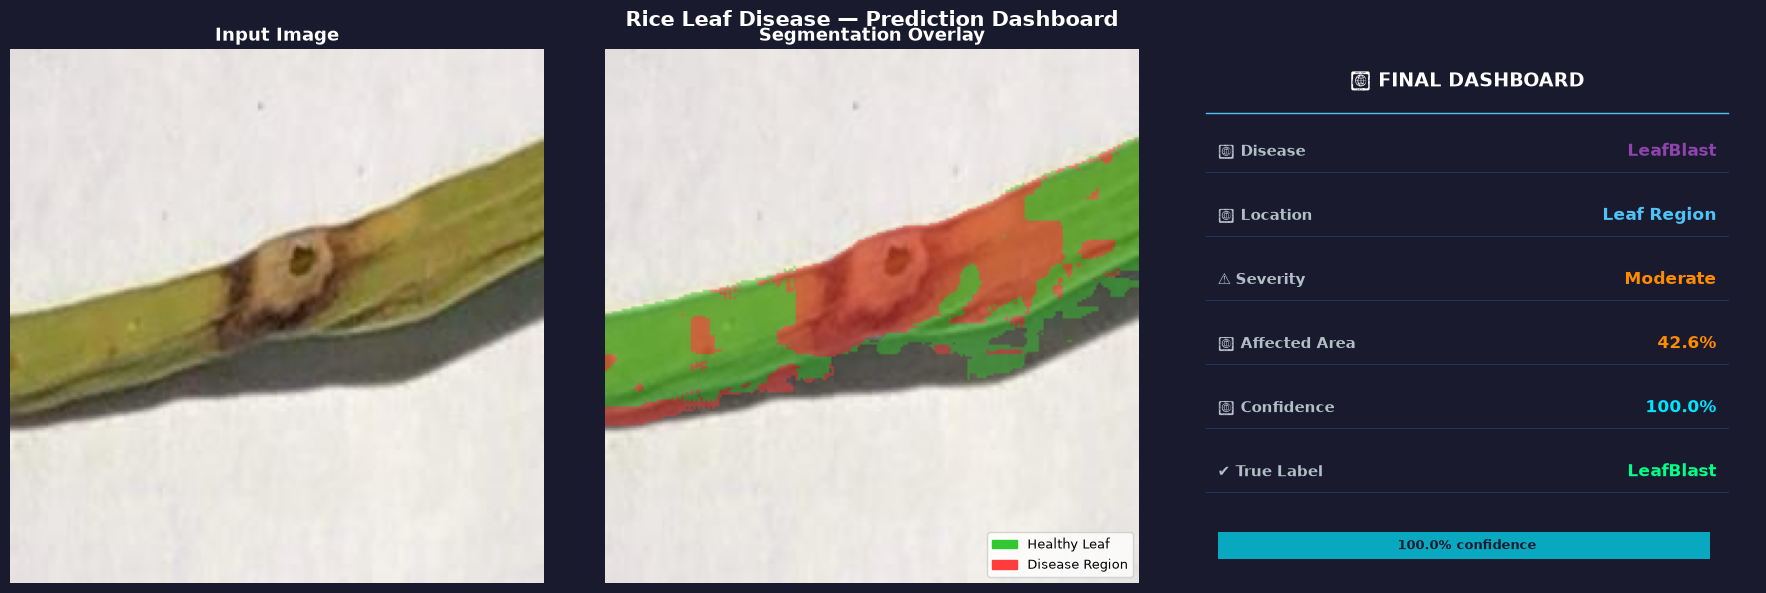

In [58]:
def show_dashboard(img_path, true_cls=None):
    disease, conf, sev_pct, sev_lvl, probs = predict_image(img_path, model)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#1A1A2E')

    # Panel 1: Original image
    axes[0].imshow(Image.open(img_path).resize(IMG_SIZE))
    axes[0].set_title('Input Image', color='white', fontsize=13, fontweight='bold')
    axes[0].axis('off')

    # Panel 2: Segmentation overlay
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(cv2.resize(img_bgr, IMG_SIZE), cv2.COLOR_BGR2RGB)
    img_hsv = cv2.cvtColor(cv2.resize(img_bgr, IMG_SIZE), cv2.COLOR_BGR2HSV)
    leaf_mask = cv2.inRange(img_hsv, np.array([25,40,40]),  np.array([95,255,255]))
    dis_mask  = cv2.bitwise_or(
        cv2.inRange(img_hsv, np.array([5, 40,40]), np.array([25,255,220])),
        cv2.inRange(img_hsv, np.array([0,  0, 0]), np.array([180,255,60])))
    overlay = img_rgb.copy()
    overlay[leaf_mask > 0] = [50, 200, 50]
    overlay[dis_mask  > 0] = [255, 60, 60]
    blended = cv2.addWeighted(img_rgb, 0.55, overlay, 0.45, 0)
    axes[1].imshow(blended)
    green_p = mpatches.Patch(color='#32C832', label='Healthy Leaf')
    red_p   = mpatches.Patch(color='#FF3C3C', label='Disease Region')
    axes[1].legend(handles=[green_p, red_p], loc='lower right', fontsize=9, framealpha=0.8)
    axes[1].set_title('Segmentation Overlay', color='white', fontsize=13, fontweight='bold')
    axes[1].axis('off')

    # Panel 3: Dashboard
    ax3 = axes[2]
    ax3.set_facecolor('#0F3460'); ax3.set_xlim(0, 10); ax3.set_ylim(0, 10); ax3.axis('off')
    SEV_CLRS = {'None':'#00FF88','Mild':'#FFE500','Moderate':'#FF8C00','Severe':'#FF2D2D'}
    sev_clr  = SEV_CLRS.get(sev_lvl, '#FFFFFF')
    dis_clr  = CLASS_COLORS[CLASS_NAMES.index(disease)]
    ax3.text(5, 9.3, '📊 FINAL DASHBOARD', ha='center', fontsize=14, fontweight='bold', color='white')
    ax3.axhline(y=8.8, xmin=0.05, xmax=0.95, color='#4FC3F7', linewidth=1)
    info = [
        ('🌿 Disease',       disease,       dis_clr),
        ('📍 Location',      'Leaf Region', '#4FC3F7'),
        ('⚠\ufe0f Severity', sev_lvl,       sev_clr),
        ('📏 Affected Area', f'{sev_pct}%', sev_clr),
        ('🎯 Confidence',    f'{conf:.1f}%','#00E5FF'),
    ]
    if true_cls:
        clr = '#00FF88' if disease == true_cls else '#FF4444'
        info.append(('\u2714\ufe0f True Label', true_cls, clr))
    y_pos = 8.0
    for key, val, clr in info:
        ax3.text(0.7, y_pos, key, fontsize=11, color='#B0BEC5', fontweight='bold')
        ax3.text(9.3, y_pos, val, fontsize=12, color=clr, fontweight='bold', ha='right')
        ax3.axhline(y=y_pos-0.3, xmin=0.05, xmax=0.95, color='#1E3A5F', linewidth=0.7)
        y_pos -= 1.2
    ax3.barh(y_pos-0.1, conf/100*8.5, left=0.7, height=0.5, color='#00E5FF', alpha=0.7)
    ax3.text(5, y_pos-0.1, f'{conf:.1f}% confidence',
             ha='center', va='center', fontsize=9, color='#1A1A2E', fontweight='bold')
    fig.suptitle('Rice Leaf Disease — Prediction Dashboard',
                 fontsize=15, fontweight='bold', color='white')
    plt.tight_layout()
    plt.savefig(r'E:\Rice Leaf Disease minor project\dashboard_prediction.png',
                dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

test_img_path, test_true_cls = random.choice(all_val_images)
print(f'Testing: {os.path.basename(test_img_path)} (True: {test_true_cls})')
show_dashboard(test_img_path, true_cls=test_true_cls)


In [59]:
final_val_acc = max(history.history['val_accuracy'])
print('\n' + '='*55)
print('  🌾  RICE LEAF DISEASE DETECTION — COMPLETE')
print('='*55)
print(f'  Model        : YOLO-Backbone + CBAM Attention')
print(f'  Classes      : {CLASS_NAMES}')
print(f'  Best Val Acc : {final_val_acc*100:.2f}%')
print('  Saved Files  :')
for f in ['model.h5', 'model_metadata.json', 'training_history.png',
           'confusion_matrix.png', 'per_class_accuracy.png',
           'test_random_predictions.png', 'dashboard_prediction.png']:
    print(f'    • {f}')
print('='*55)
print('Next Step -> Build Flask/FastAPI backend using model.h5')



  🌾  RICE LEAF DISEASE DETECTION — COMPLETE
  Model        : YOLO-Backbone + CBAM Attention
  Classes      : ['BrownSpot', 'Healthy', 'Hispa', 'LeafBlast']
  Best Val Acc : 97.03%
  Saved Files  :
    • model.h5
    • model_metadata.json
    • training_history.png
    • confusion_matrix.png
    • per_class_accuracy.png
    • test_random_predictions.png
    • dashboard_prediction.png
Next Step -> Build Flask/FastAPI backend using model.h5
